In [1]:
import os
import xarray as xr
import datetime as dt
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import geopandas as gpd
import rasterio
import numpy as np
from shapely.geometry import Point
from rasterio.features import geometry_mask
from rasterio.transform import from_bounds
from matplotlib.colors import LinearSegmentedColormap

In [2]:
folder_project = 'D:/JALANGLOIS/'
start_date = datetime(2022, 1, 1)
end_date = datetime(2022, 12, 31)
year = start_date.year
hemisphere = 'N'
region = 'aac'

yeardoy_start = start_date.strftime('%Y%j')
yeardoy_end = end_date.strftime('%Y%j')

file = os.path.join(folder_project, 'ROS_NC', 'with_snow','grp_corr_tb_snow_%s_%s_%s.nc'%(str(yeardoy_start), str(yeardoy_end), region))
ds = xr.open_dataset(file)
print(ds)


<xarray.Dataset>
Dimensions:             (orbit: 2, y: 605, x: 611, time: 365)
Coordinates:
  * orbit               (orbit) object 'E' 'M'
  * y                   (y) float64 1.17e+06 1.167e+06 ... -7.141e+05 -7.172e+05
  * x                   (x) float64 -2.323e+06 -2.32e+06 ... -4.172e+05
  * time                (time) datetime64[ns] 2022-01-01 ... 2022-12-31
    Lambert_Conformal   int32 ...
    projection          int32 ...
Data variables: (12/13)
    crs                 int32 ...
    TB_19H              (orbit, time, y, x) float64 ...
    TB_std_dev_19H      (orbit, time, y, x) float32 ...
    TB_19V              (orbit, time, y, x) float64 ...
    TB_std_dev_19V      (orbit, time, y, x) float32 ...
    TB_37H              (orbit, time, y, x) float64 ...
    ...                  ...
    TB_37V              (orbit, time, y, x) float64 ...
    TB_std_dev_37V      (orbit, time, y, x) float32 ...
    pr_wtr              (time, y, x) float64 ...
    GRP                 (orbit, time, y,

In [3]:
#Add a variables ROS to 1 if IMS_Surface_Values is 4 and GRP < -10
ds['ROS'] = xr.where((ds['IMS_Surface_Values'] == 4) & (ds['GRP'] < -10), 1, 0)
ds

<xarray.Dataset>
Dimensions:             (orbit: 2, y: 605, x: 611, time: 365)
Coordinates:
  * orbit               (orbit) object 'E' 'M'
  * y                   (y) float64 1.17e+06 1.167e+06 ... -7.141e+05 -7.172e+05
  * x                   (x) float64 -2.323e+06 -2.32e+06 ... -4.172e+05
  * time                (time) datetime64[ns] 2022-01-01 ... 2022-12-31
    Lambert_Conformal   int32 ...
    projection          int32 ...
Data variables: (12/14)
    crs                 int32 ...
    TB_19H              (orbit, time, y, x) float64 ...
    TB_std_dev_19H      (orbit, time, y, x) float32 ...
    TB_19V              (orbit, time, y, x) float64 ...
    TB_std_dev_19V      (orbit, time, y, x) float32 ...
    TB_37H              (orbit, time, y, x) float64 ...
    ...                  ...
    TB_std_dev_37V      (orbit, time, y, x) float32 ...
    pr_wtr              (time, y, x) float64 ...
    GRP                 (orbit, time, y, x) float64 nan 1.102 1.108 ... nan nan
    GRP_std_dev         (orbit, time, y, x) float64 ...
    IMS_Surface_Values  (time, y, x) float64 nan nan nan nan ... nan nan nan nan
    ROS                 (time, y, x, orbit) int32 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
Attributes: (12/78)
    references:                    Long, D. G. and M. J. Brodzik. 2016. Optim...
    title:                         MEaSUREs Calibrated Passive Microwave Dail...
    id:                            10.5067/MEASURES/CRYOSPHERE/nsidc-0630.001
    summary:                       An improved, enhanced-resolution, gridded ...
    project:                       An improved, enhanced-resolution, gridded ...
    contributor_name:              Mary J. Brodzik, David G. Long, Richard L....
    ...                            ...
    input_file12:                  CSU_SSMIS_ICDR_V01R01_F18_D20220101_S2011_...
    input_file13:                  CSU_SSMIS_ICDR_V01R01_F18_D20220101_S2153_...
    input_file14:                  CSU_SSMIS_ICDR_V01R01_F18_D20220101_S2335_...
    input_file15:                  CSU_SSMIS_ICDR_V01R01_F18_D20220102_S0116_...
    input_file16:                  CSU_SSMIS_ICDR_V01R01_F18_D20220102_S0258_...
    input_file17:                  CSU_SSMIS_ICDR_V01R01_F18_D20220102_S0440_...

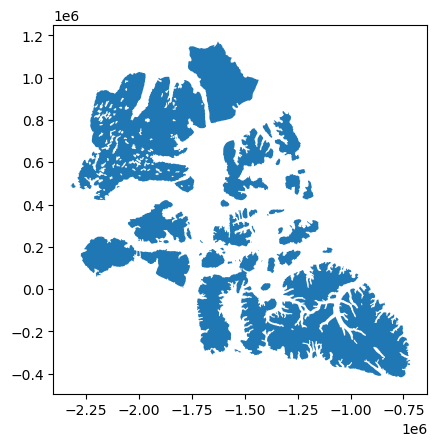

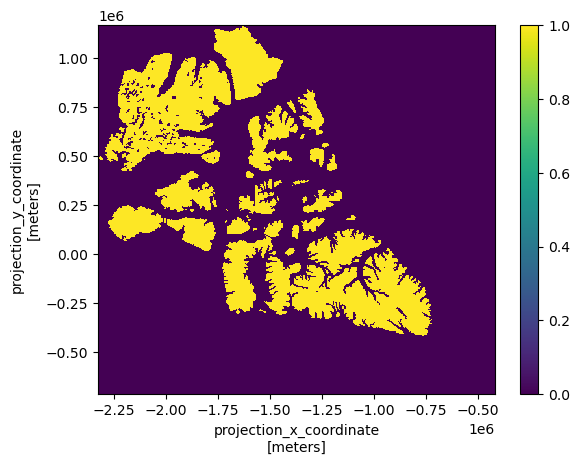

In [4]:
#read region shapefile (negative buffer of 1500 m) and mask the ROS variable
region_path = os.path.join(folder_project,'regions', region, '%s_moins_1500m.shp'%(region))  
gdf = gpd.read_file(region_path)

gdf = gdf.to_crs(6931)
#print(gdf)

# Get the coordinates of the dataset
x = ds['x'].values
y = ds['y'].values

# Create a 2D array of coordinates (x, y)
x2d, y2d = np.meshgrid(x, y)
coords = np.dstack((x2d, y2d))

# Get the geometries from the shapefile
geometries = gdf.geometry

#plot the geometries
gdf.plot()
plt.show()

# Define the affine transformation using the bounds of the dataset
transform = from_bounds(x.min(), y.min(), x.max(), y.max(), len(x), len(y))


# Use rasterio.features.geometry_mask to create the mask
mask = geometry_mask([geom for geom in geometries],
                     transform=transform,
                     invert=True,
                     out_shape=(len(y), len(x)))

# Create a DataArray for the mask
mask_da = xr.DataArray(mask, coords=[ds['y'], ds['x']], dims=['y', 'x'])

mask_da.plot()
plt.show()


In [5]:
# Apply the mask to your dataset
ds['ROS'] = ds['ROS'].where(mask_da, drop=False)


In [6]:
#Calculate the number of ROS per month for both orbit (cumulative)
ros_cumulated_per_month = ds['ROS'].groupby('time.month').sum(dim='time')

ros_cumulated_per_month


<xarray.DataArray 'ROS' (month: 12, y: 605, x: 611, orbit: 2)>
array([[[[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
...
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]]]])
Coordinates:
  * orbit              (orbit) object 'E' 'M'
  * y                  (y) float64 1.17e+06 1.167e+06 ... -7.141e+05 -7.172e+05
  * x                  (x) float64 -2.323e+06 -2.32e+06 ... -4.172e+05
    Lambert_Conformal  int32 ...
    projection         int32 ...
  * month              (month) int64 1 2 3 4 5 6 7 8 9 10 11 12

In [7]:
ros_cumulated_per_month = ros_cumulated_per_month.where(mask_da, drop=False)

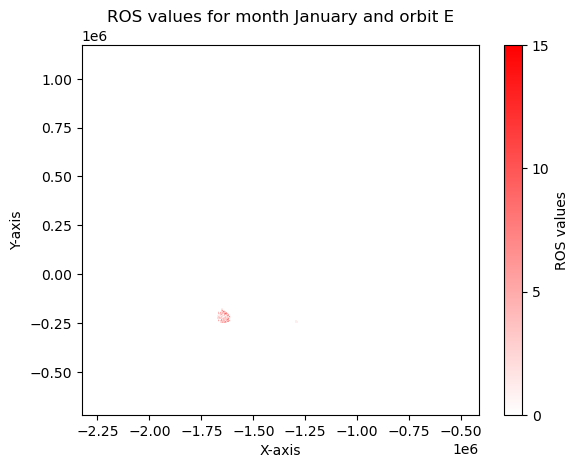

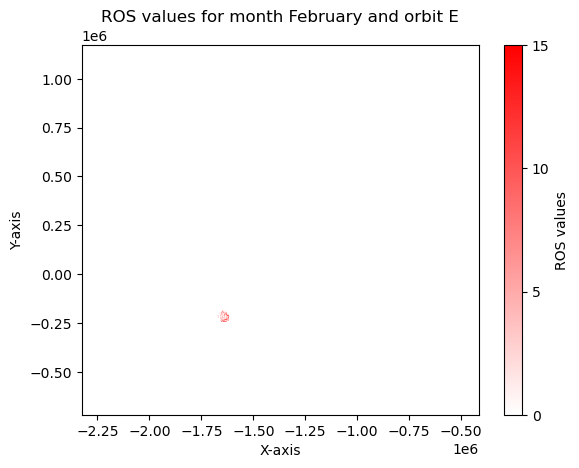

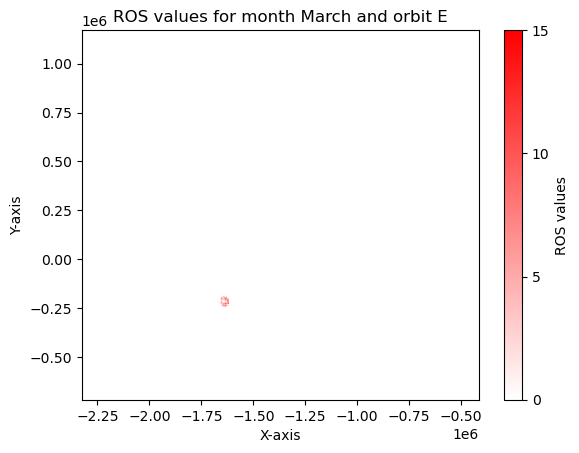

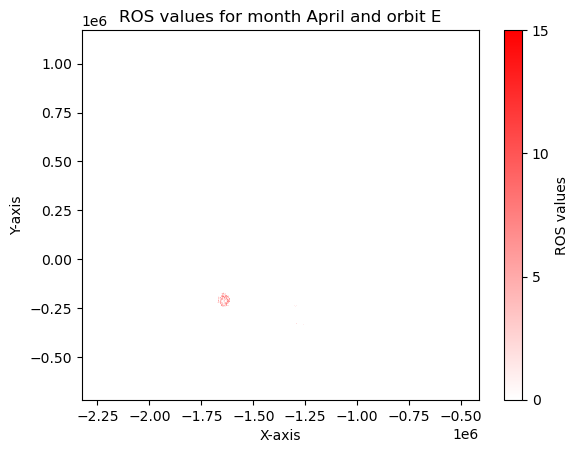

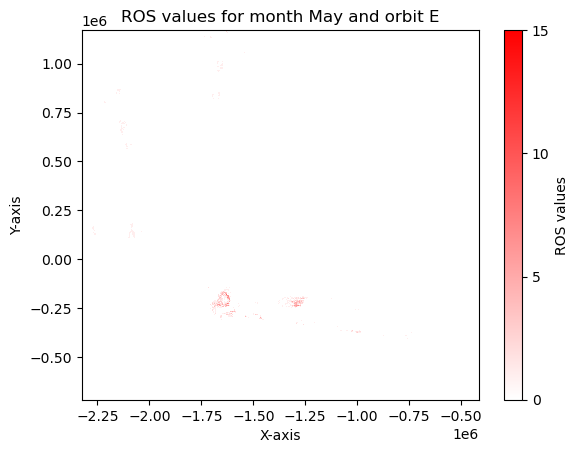

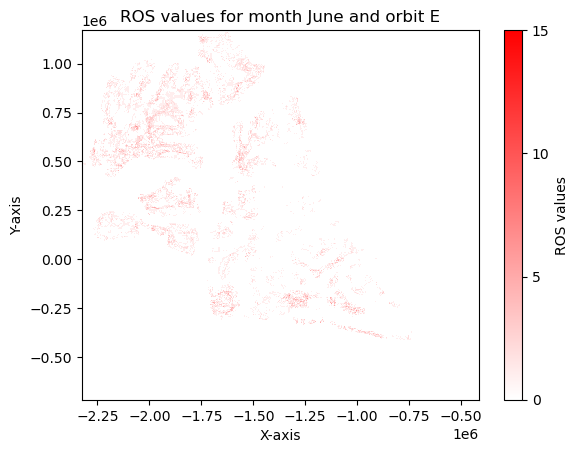

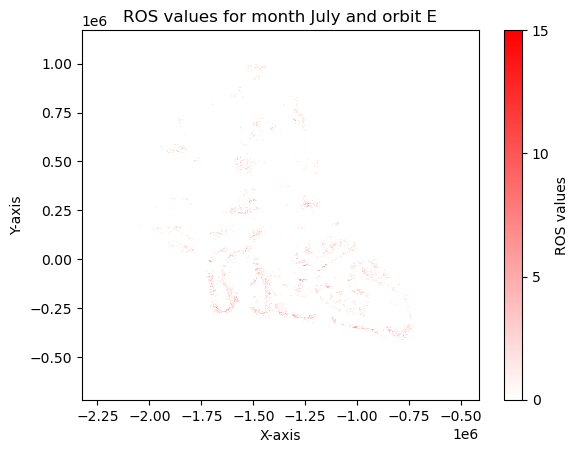

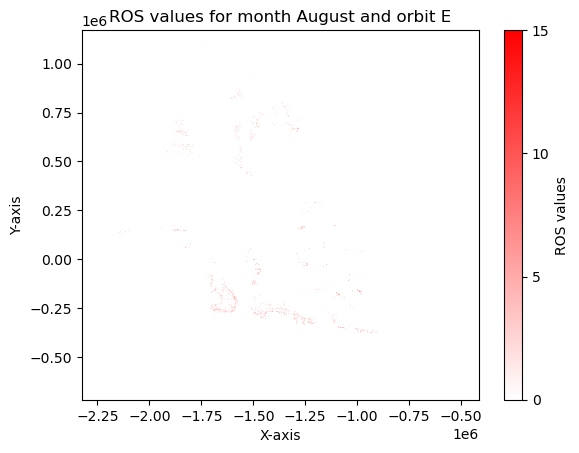

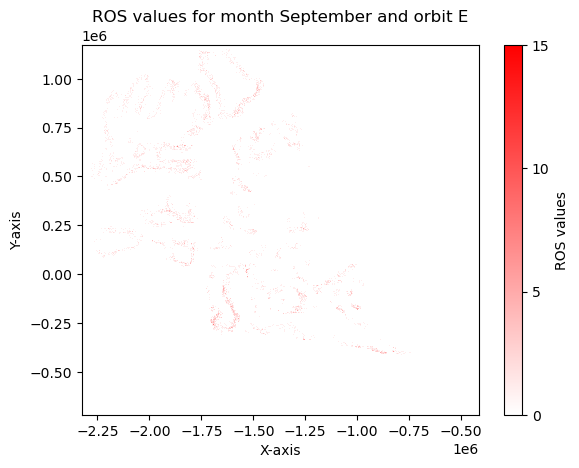

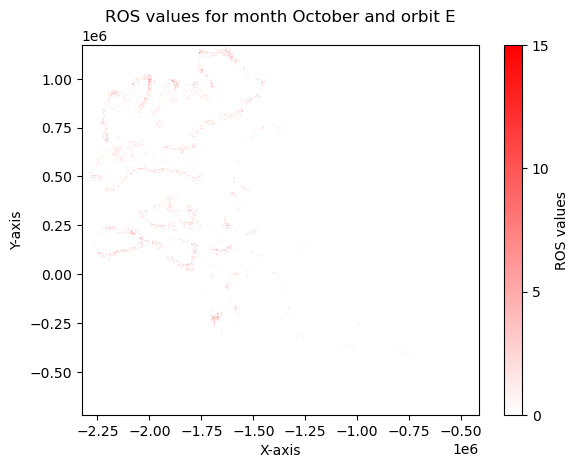

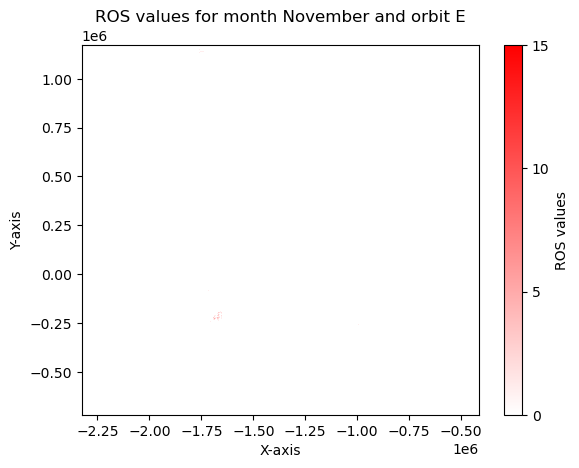

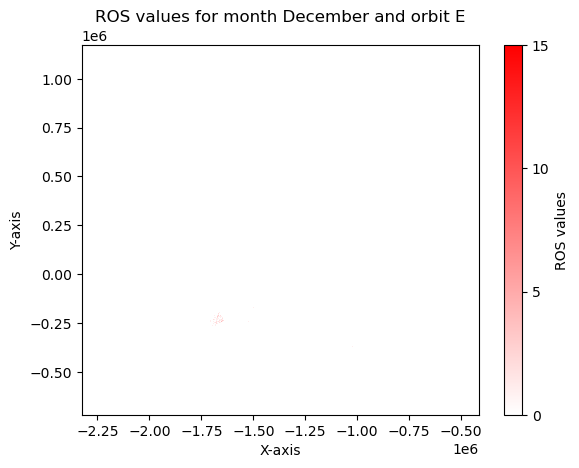

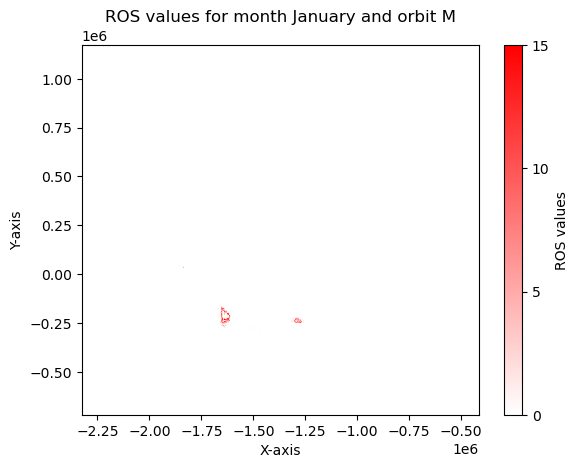

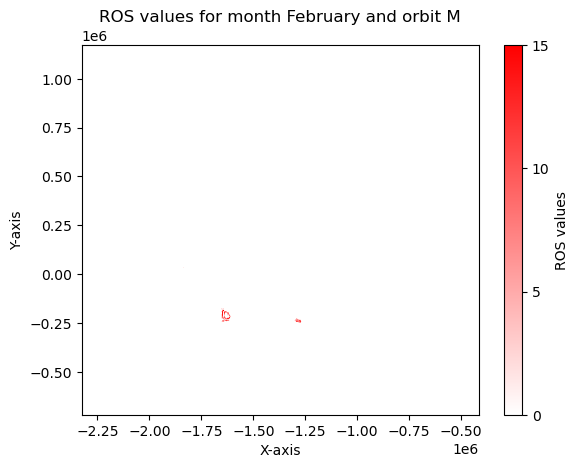

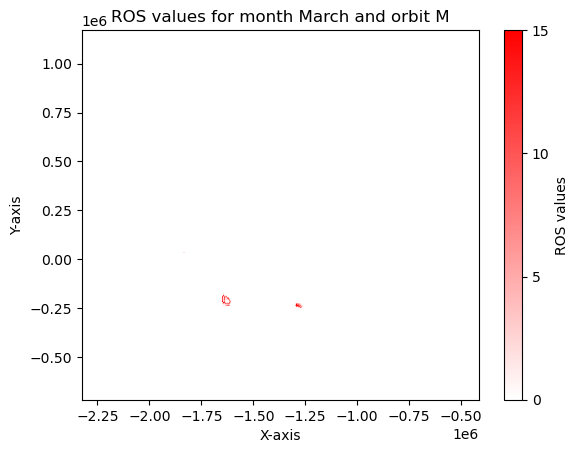

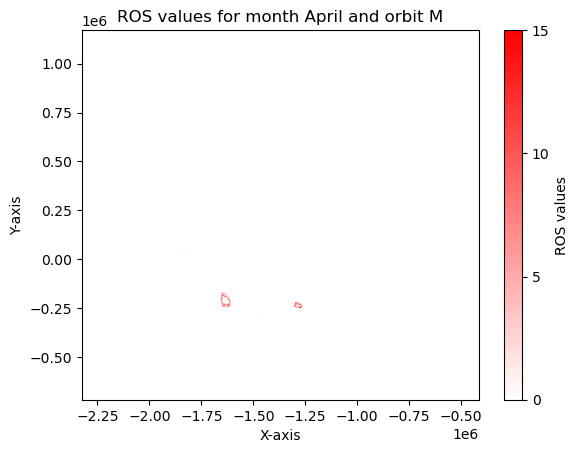

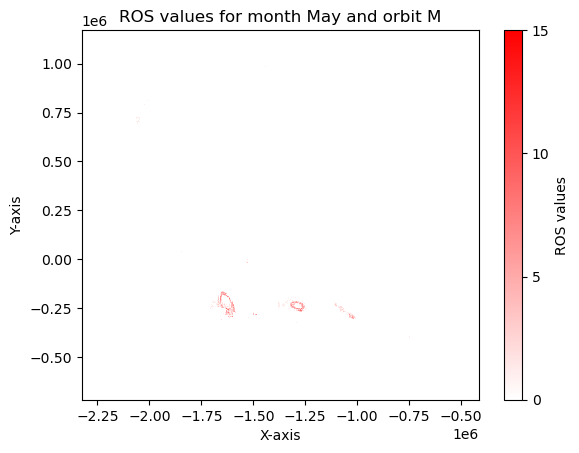

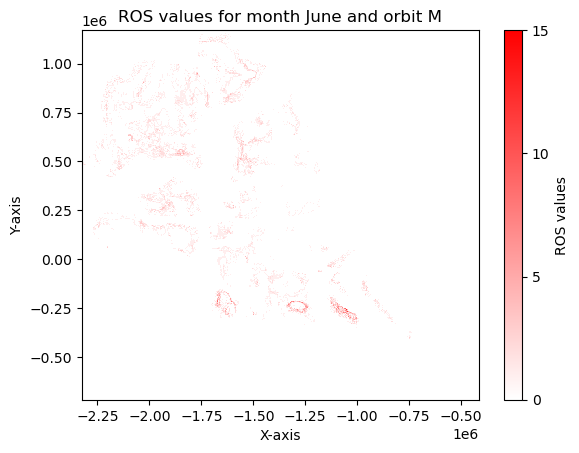

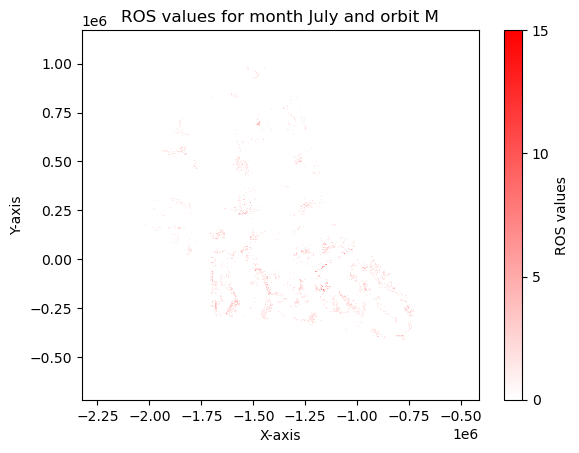

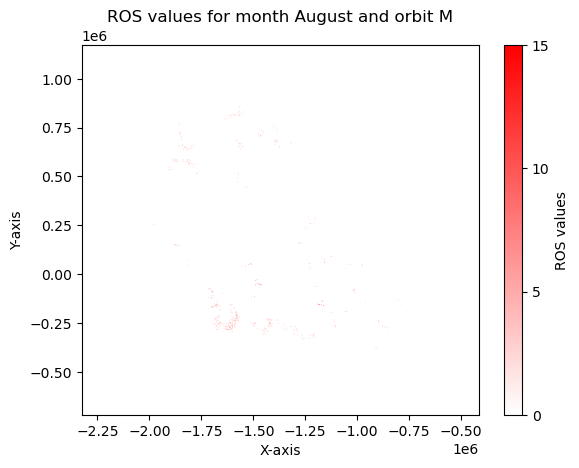

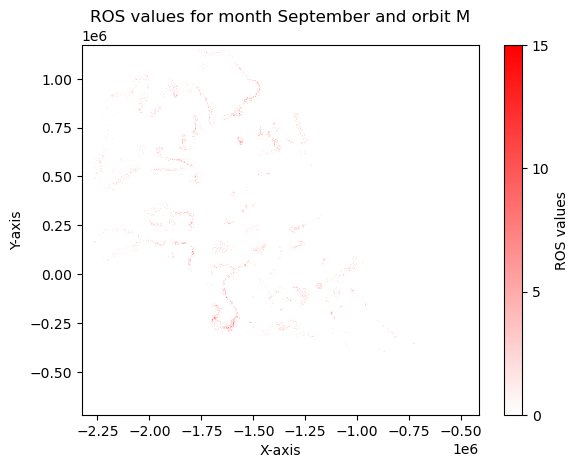

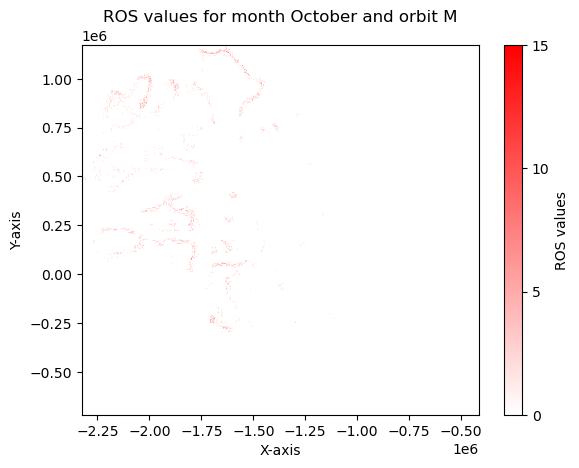

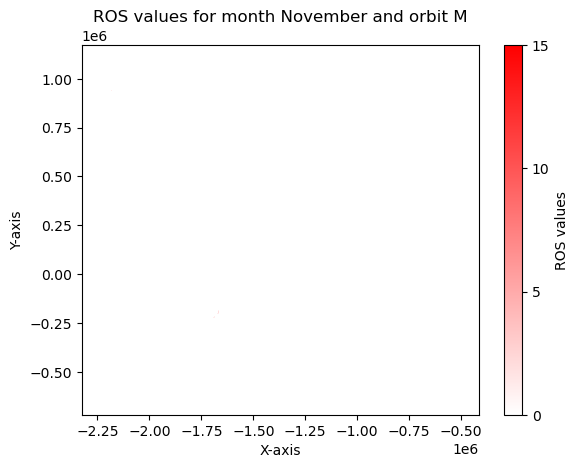

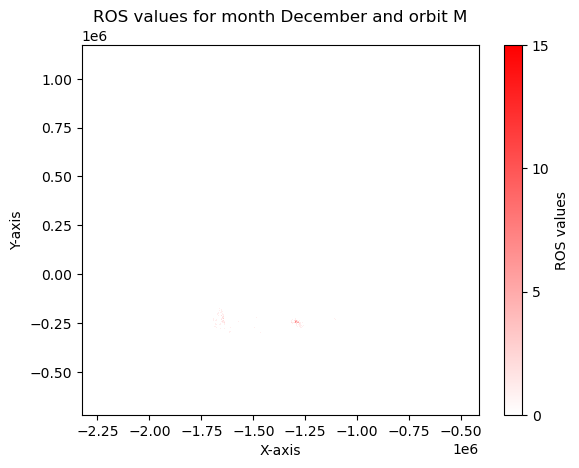

In [13]:
orbits = ['E', 'M']
for orbit in orbits:
    #iterate over the months and plot the ROS
    for month in ros_cumulated_per_month.month.values:
        subset = ros_cumulated_per_month.sel(month=month, orbit=orbit)
        # Define the custom colormap from white to red
        colors = [(1, 1, 1), (1, 0, 0)]  # From white to red
        n_bins = 256  # Use 256 bins for the colormap
        cmap_name = 'white_to_red'
        cm = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)

        # Plot the DataArray using pcolormesh
        fig, ax = plt.subplots()
        c = ax.pcolormesh(subset['x'], subset['y'], subset, cmap=cm, vmin=0, vmax=15)

        # Add a colorbar
        cbar = fig.colorbar(c, ax=ax)
        cbar.set_label('ROS values')
        cbar.set_ticks([0, 5, 10, 15])
        cbar.set_ticklabels(['0', '5', '10', '15'])

        # Set labels and title
        ax.set_xlabel('X-axis')
        ax.set_ylabel('Y-axis')
        ax.set_title('ROS values for month %s and orbit %s'%(str(dt.date(1900, month, 1).strftime('%B')), orbit))

        plt.show()

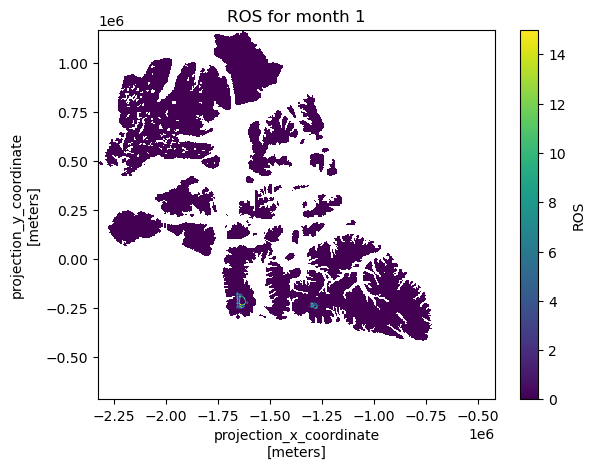

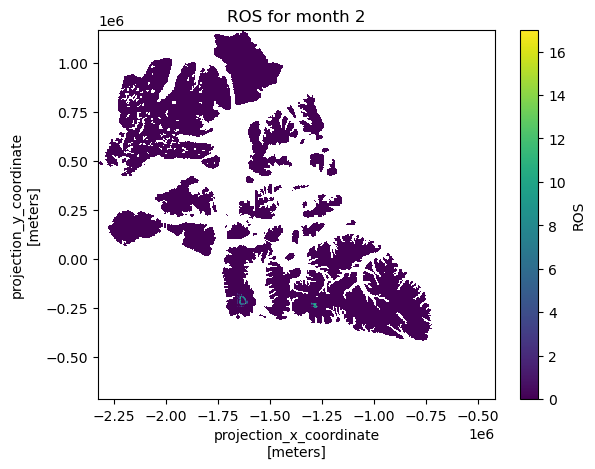

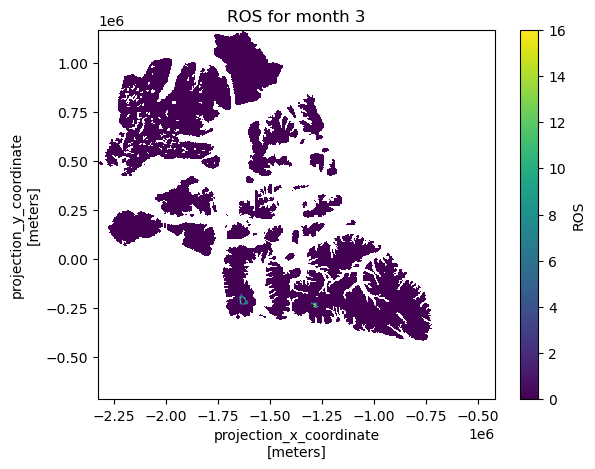

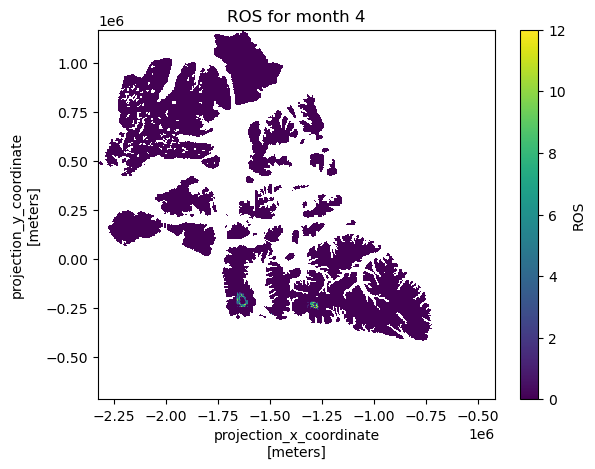

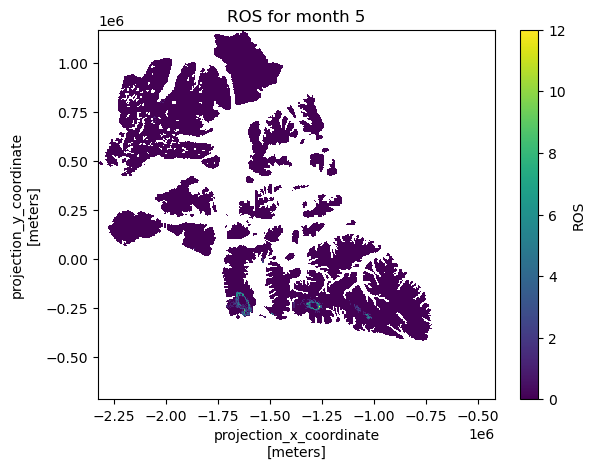

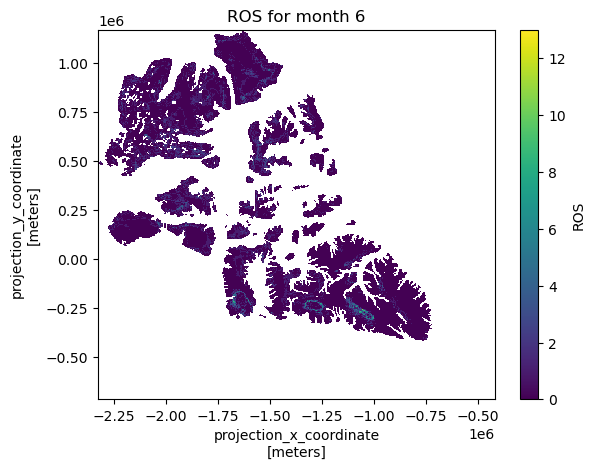

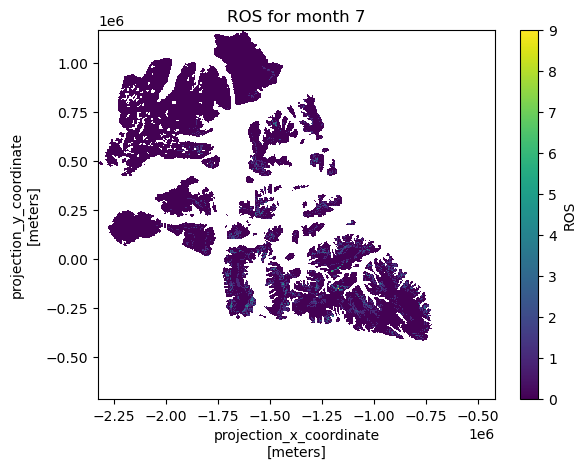

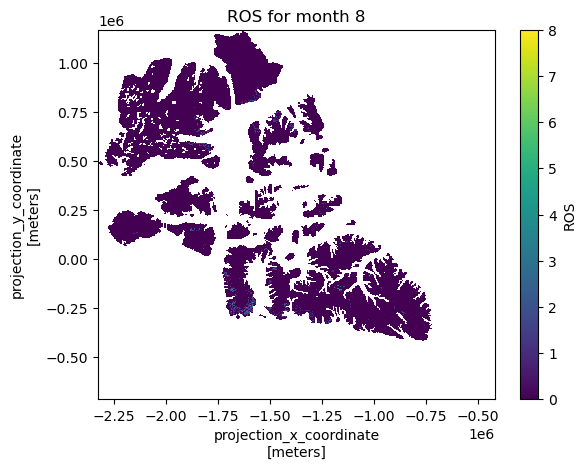

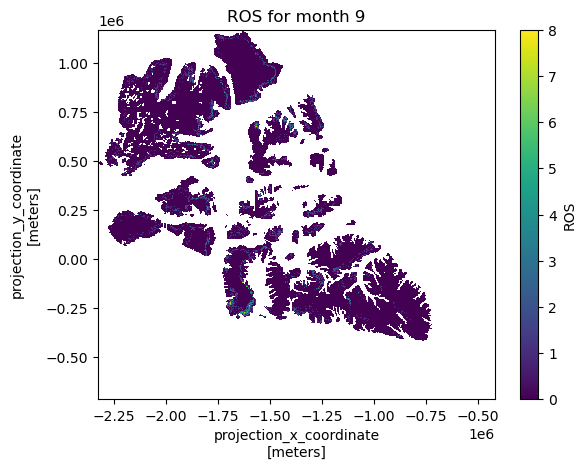

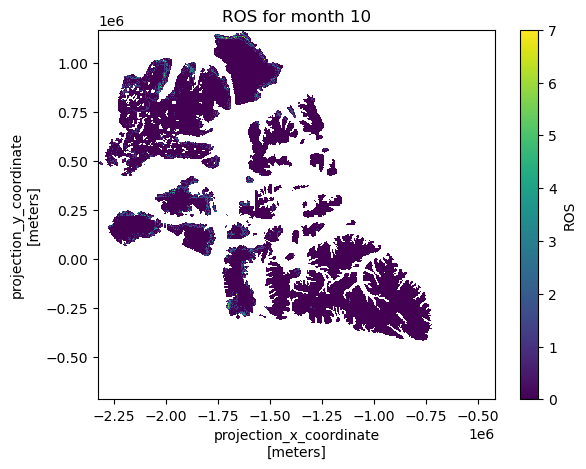

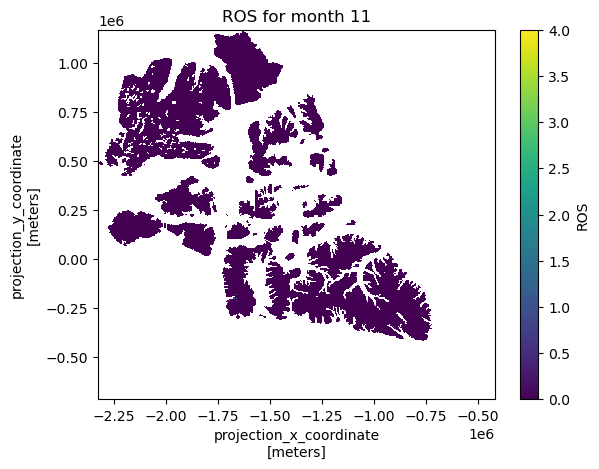

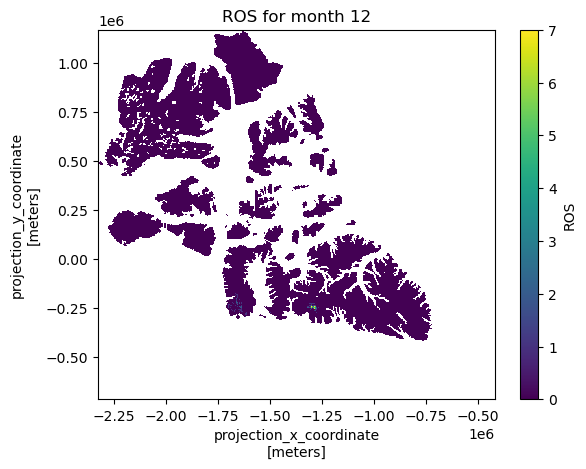

In [11]:

#iterate over the months and plot the ROS
for month in ros_cumulated_per_month.month.values:

    ros_cumulated_per_month.sel(month=month, orbit='M').plot()

    
    plt.title('ROS for month %s'%month)
    plt.show()


In [7]:
#write to netcdf
file_out = os.path.join(folder_project, 'ROS_NC', 'with_snow','grp_corr_tb_snow_%s_%s_%s.nc'%(str(yeardoy_start), str(yeardoy_end), region))
ds.to_netcdf(file_out)

2022-10-01


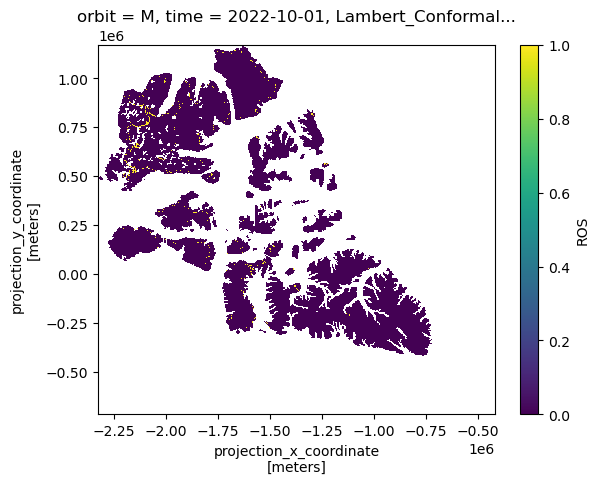

2022-10-02


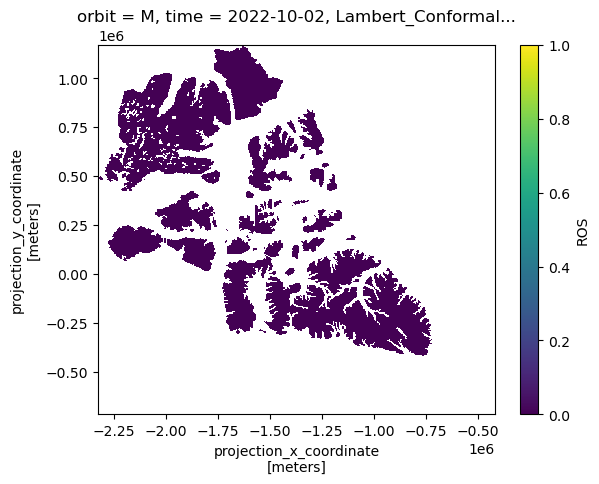

2022-10-03


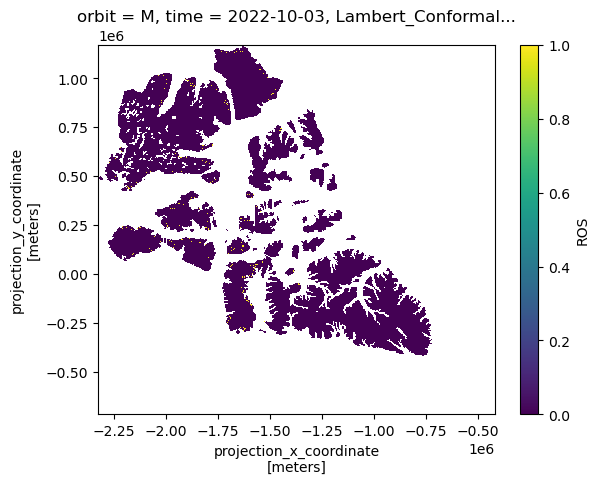

2022-10-04


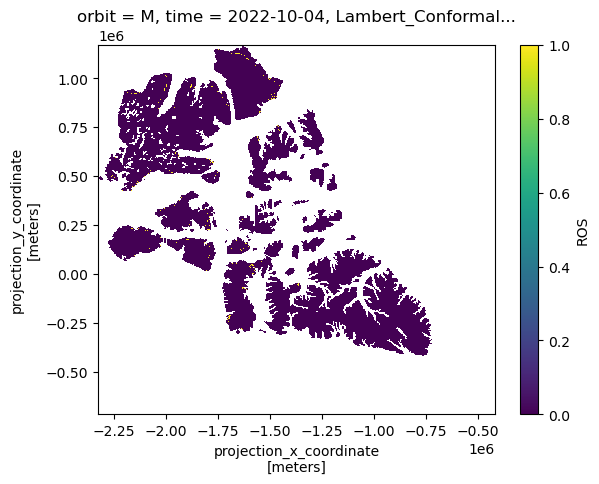

2022-10-05


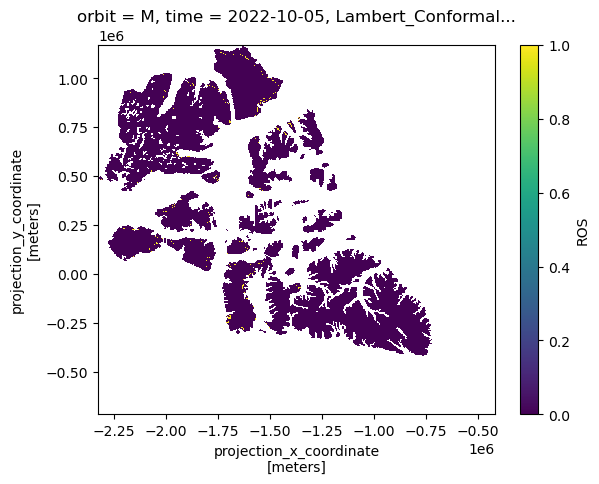

2022-10-06


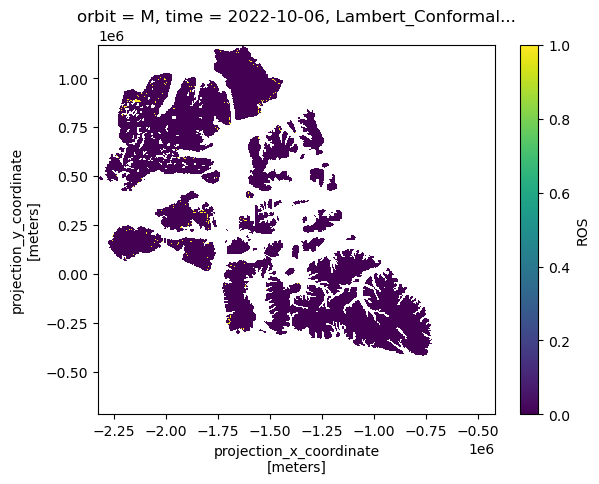

2022-10-07


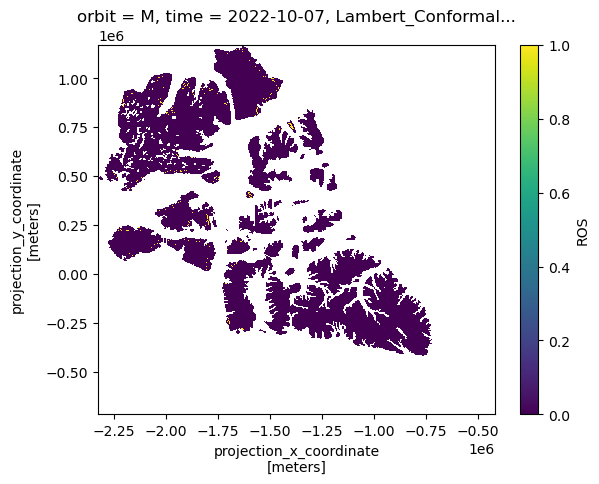

2022-10-08


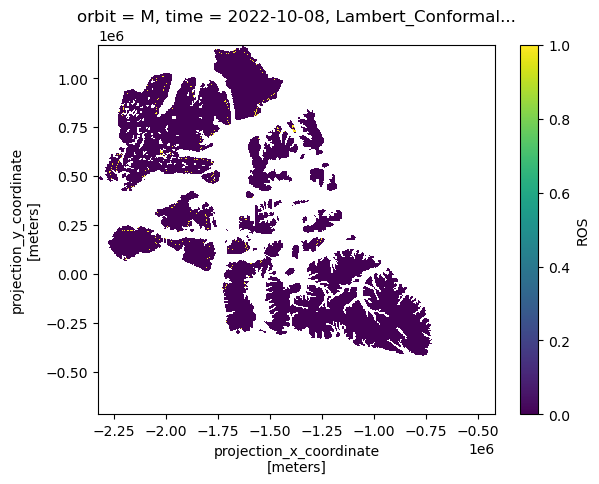

2022-10-09


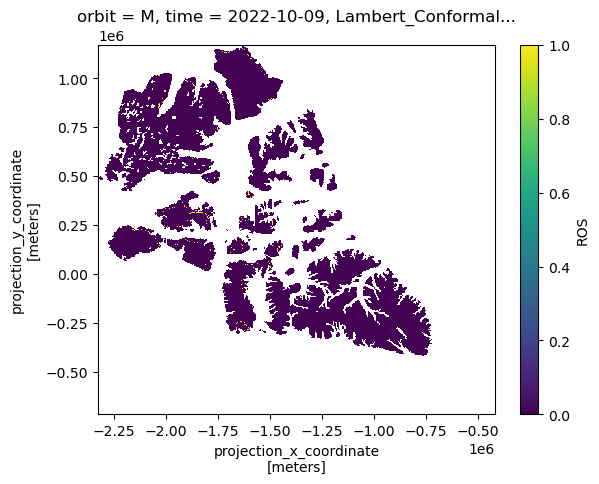

2022-10-10


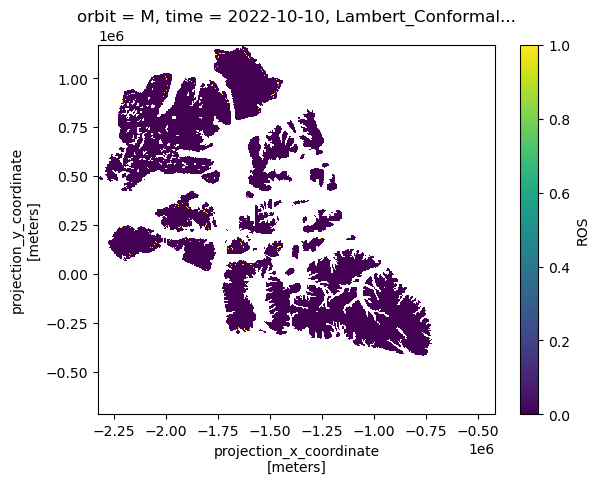

2022-10-11


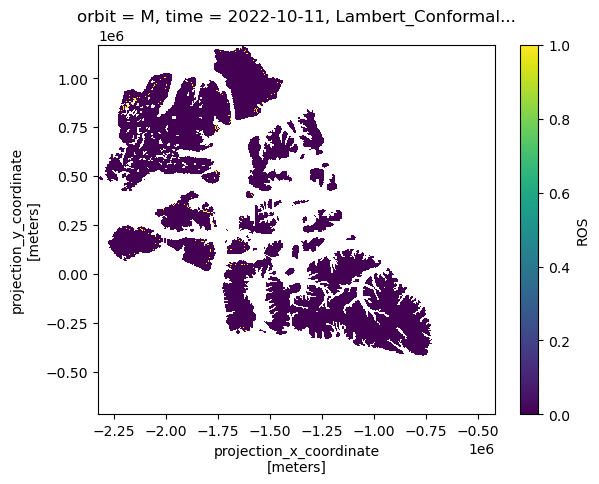

2022-10-12


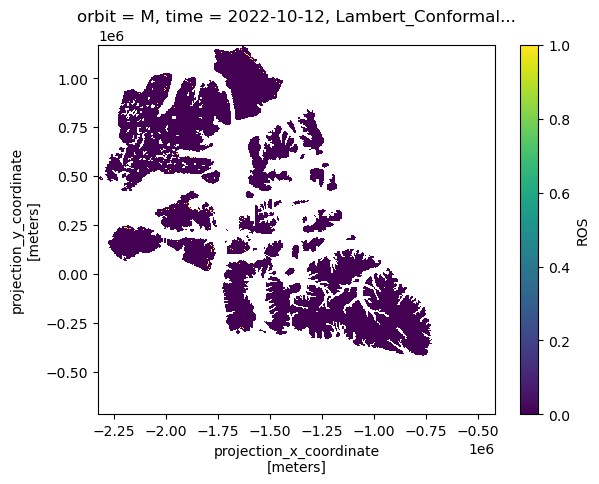

2022-10-13


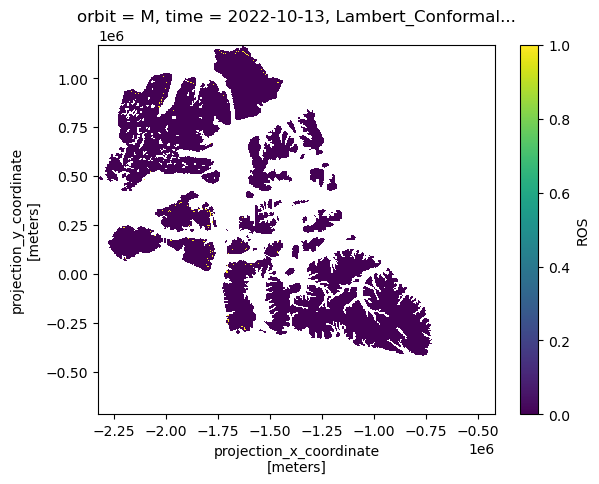

2022-10-14


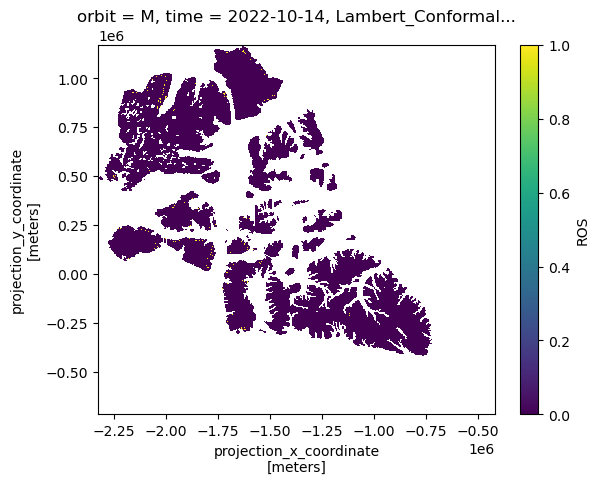

2022-10-15


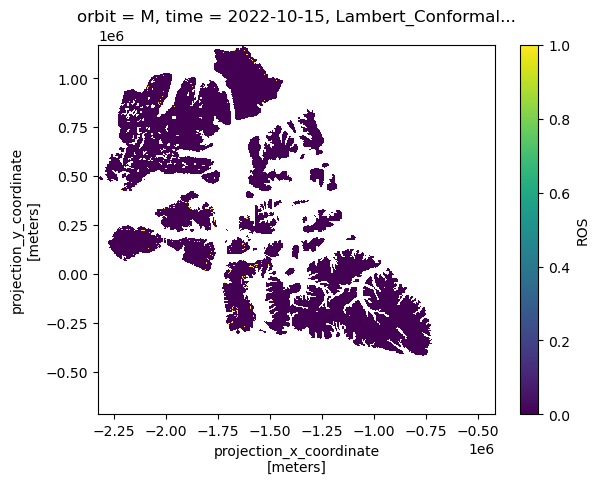

2022-10-16


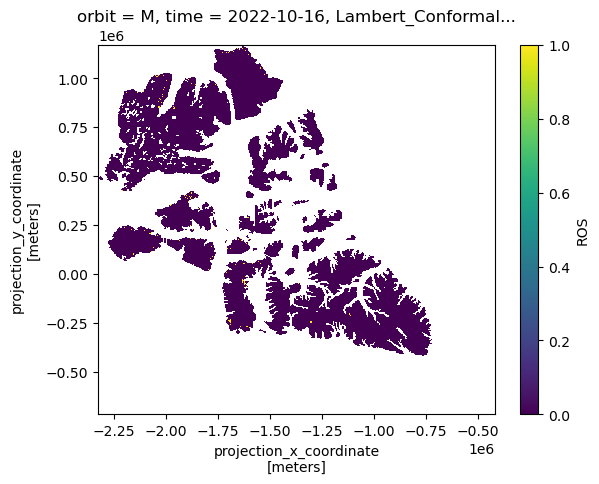

2022-10-17


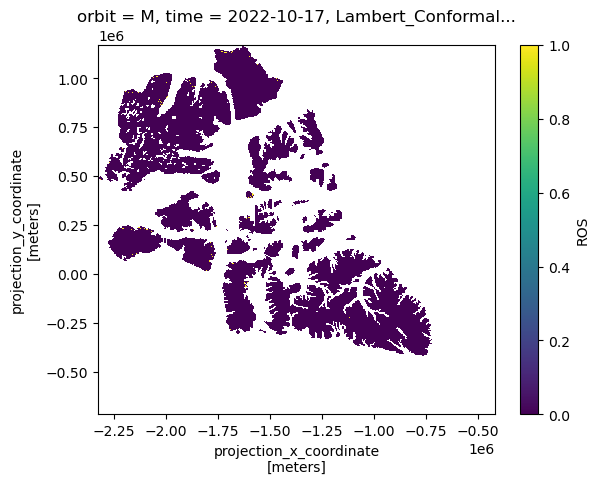

2022-10-18


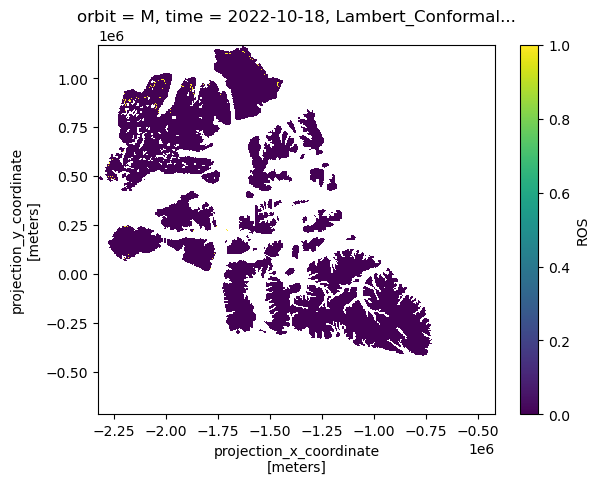

2022-10-19


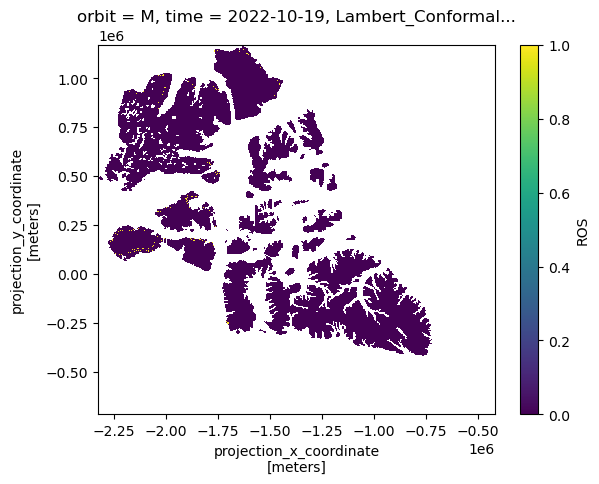

2022-10-20


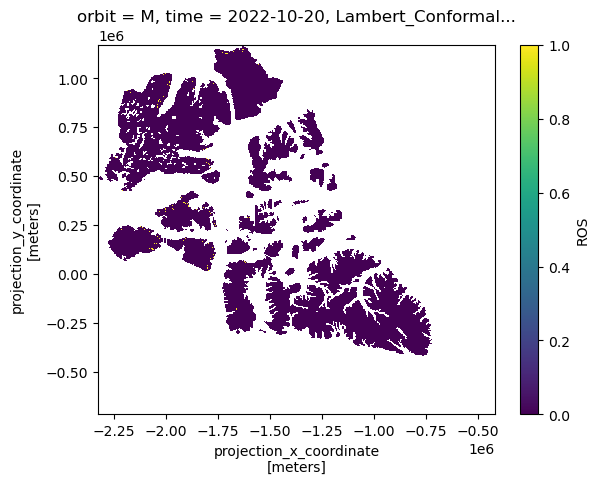

2022-10-21


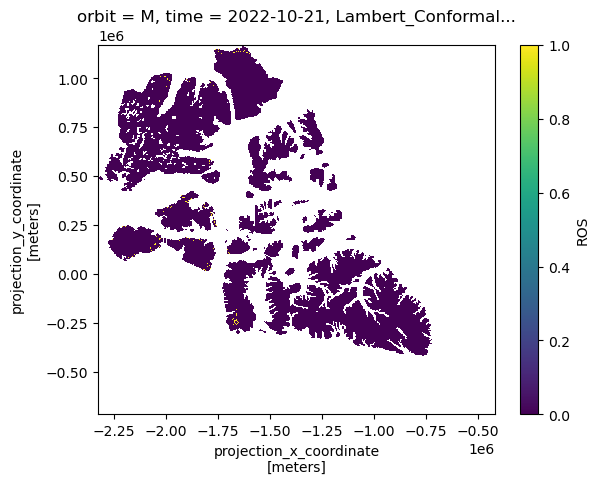

2022-10-22


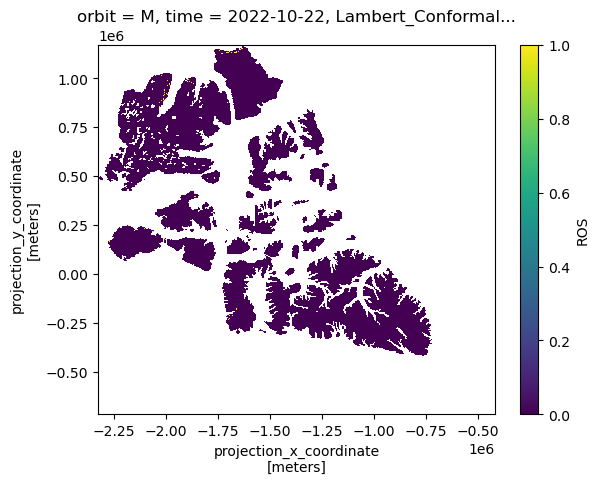

2022-10-23


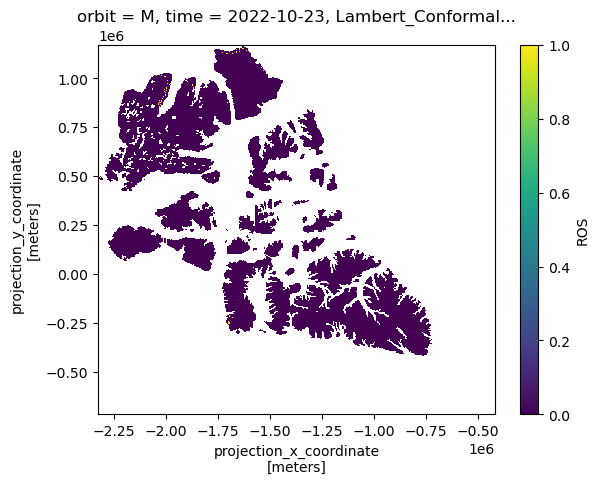

2022-10-24


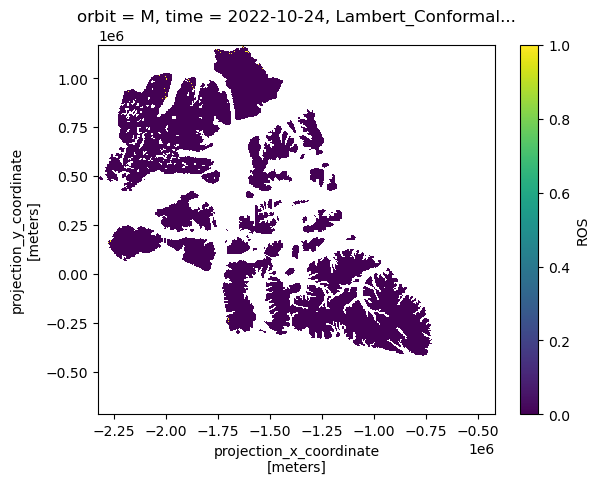

2022-10-25


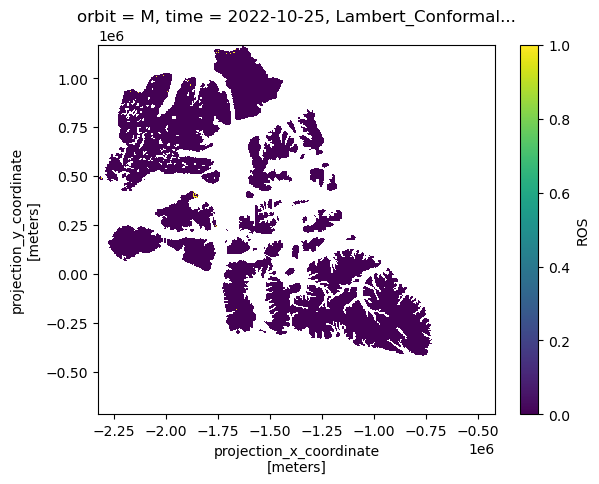

2022-10-26


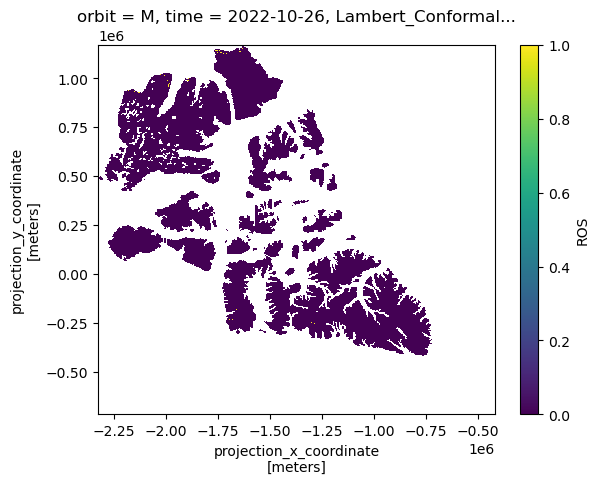

2022-10-27


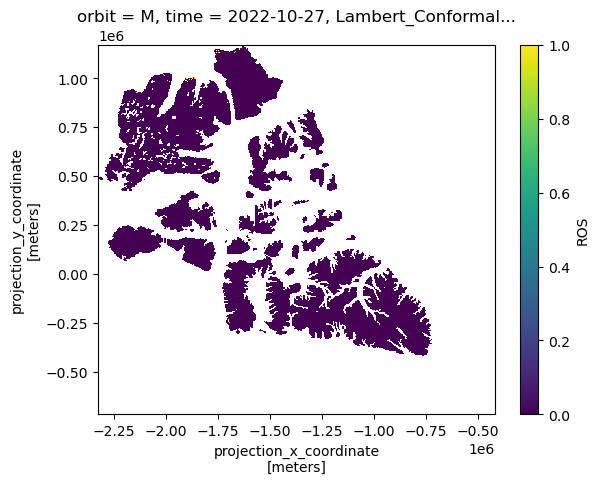

2022-10-28


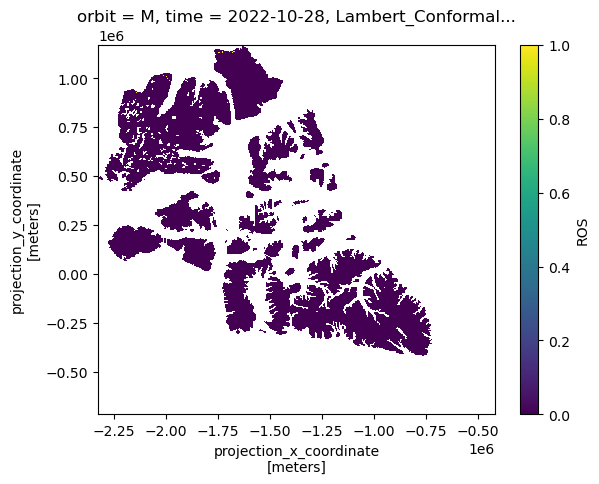

2022-10-29


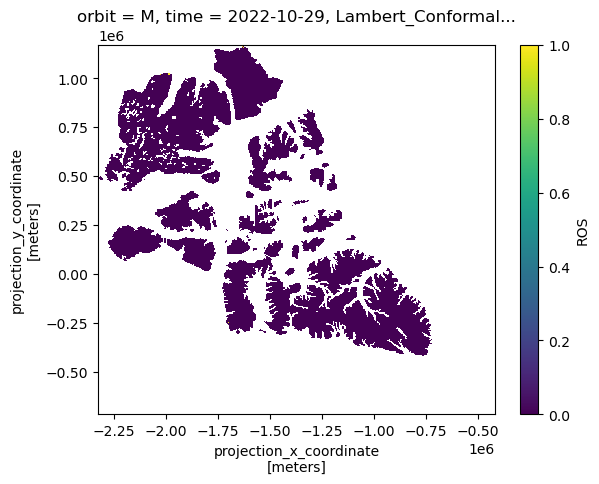

2022-10-30


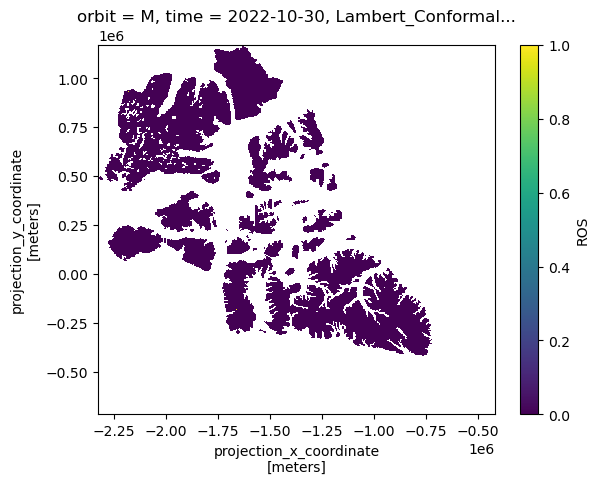

In [41]:
#iterate from start_date for a number of days
time = datetime(2022,10,1)
nb_days = 30
orbit = 'M'

# Iterate over the range of dates
for i in range(nb_days):
    current_date = time + timedelta(days=i)
    print(current_date.strftime('%Y-%m-%d'))

    ds['ROS'].sel(time=current_date, orbit=orbit).plot(vmin=0,vmax=1)
    plt.show()
#ds['GRP'].sel(time=time, orbit=orbit).plot(vmin=-5,vmax=5)
#plt.show()
